# Project 1

## Overview

In this project, you will build models that classify news articles by topic. You will represent each article with TF-IDF features (see 4) and train two classifiers introduced in this module: logistic regression and a multilayer perceptron (MLP). Transformers and pretrained language models are outside the scope of this project.

You will investigate whether models trained on one news dataset generalize to unseen in-domain articles, transfer to articles collected from a different source, and adapt when category definitions change. You will also study how regularization and limited target-domain training data affect performance.

Key concepts of this project include:
- construct a reproducible text-classification pipeline without evaluation-data leakage;
- compare a linear classifier with a nonlinear neural-network classifier;
- select hyperparameters using validation data and appropriate evaluation metrics;
- analyze in-domain performance, cross-dataset transfer, and category mismatch; and
- support quantitative results with error analysis and clear explanations.


### TODOs

[ ] Remove unnecessary (debug purpose) prints and displays

[x] Compute the training/validation accuracy for both LogRes & MLP

[ ] Compute macro-F1 for both LogRes & MLP

[ ] Compute F1 for both LogRes & MLP

[ ] Compute per-class precision for both LogRes & MLP

[ ] Compute Recall for both LogRes & MLP

[x] Refit the TF-IDF vectorizer & re-evaluate the model

[ ] Refactor training/validation loops

### Dependencies & Notebook Configurations

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

In [2]:
# for reproducibility
np.random.seed(0)
torch.manual_seed(0)

In [3]:
# Use GPU if available
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

USE_CUDA = DEVICE.type  == "cuda"

print(f"DEVICE: {DEVICE}")
print(f"USE_CUDA: {USE_CUDA}")

DEVICE: cuda
USE_CUDA: True


## Data Load & Preprocessing

In [4]:
# Set A
SOURCE_A_TRAIN = pd.read_csv("./dataset/dataset_a_train.csv")
SOURCE_A_TEST = pd.read_csv("./dataset/dataset_a_test.csv")

display(SOURCE_A_TRAIN.head())
display(SOURCE_A_TEST.head())

# Set B
SOURCE_B_TEST = pd.read_csv("./dataset/dataset_b_test.csv")

display(SOURCE_B_TEST.head())

# Set C
SOURCE_C_TRAIN = pd.read_csv("./dataset/dataset_c_train.csv")
SOURCE_C_TEST = pd.read_csv("./dataset/dataset_c_test.csv")

display(SOURCE_C_TRAIN.head())
display(SOURCE_C_TEST.head())

,Label,Title,Description
0,3,Huge California Gas Leak Will Come To An End I...,A relief well that the company began drilling ...
1,3,TheFuturein5 Episode 25: Why This Time It's Di...,"As the saying goes, ""Either you disrupt or get..."
2,3,Enough About Disruption: We're in the Golden A...,Those not plunging into the brave new world on...
3,3,Mind Your Manners Tips for Effective Cross-Cul...,Communicating across cultures in the business ...
4,3,Uber Refunds Fares After Uproar Over London Te...,Prices soared as people scrambled to flee the ...


,Label,Title,Description
0,4,Police Officials Tell Congress Encryption Hurt...,The encryption debate returned to Congress on ...
1,2,Wisconsin Apologizes For Mishandling Fans Depi...,“We will learn from this incident and do bette...
2,2,Karl-Anthony Towns Carves His Own Path As The ...,The Minnesota center is a playmaking 7-footer ...
3,2,High School Basketball Player Pulls Off Jaw-Dr...,"Tyler Williams said he wanted to ""spice up"" th..."
4,3,"Toys R Us May Shut Down All U.S. Operations, I...","The liquidation could put up to 33,000 U.S. jo..."


,Label,Title,Description
0,3,Crossrail link 'to get go-ahead',"The £10bn Crossrail transport plan, backed by..."
1,5,Uganda bans Vagina Monologues,Uganda's authorities have banned the play The...
2,1,Campaign 'cold calls' questioned,Labour and the Conservatives are still teleph...
3,4,US peer-to-peer pirates convicted,The first convictions for piracy over peer-to...
4,2,Moyes U-turn on Beattie dismissal,Everton manager David Moyes will discipline s...


,Label,Title,Description
0,1,US eyes cut in troops in Afghanistan,"KABUL, Afghanistan -- The United States could ..."
1,1,"Soldier, 4 Militants Die in Renewed Gaza Fighting",GAZA (Reuters) - Four Palestinian militants a...
2,1,Brazilian Soldier Wounded in Haiti Unrest,A Brazilian soldier with the UN peacekeeping f...
3,1,"Iraq Bombings Kill 35 Youths, Hurt Scores (AP)",AP - A string of bombs killed 35 children and ...
4,1,Airstrike said to kill 50 at suspected Qaeda site,PAKISTAN WANA -- Pakistani warplanes pummeled ...


,Label,Title,Description
0,4,New Internet magazine grooms women for jihad,DUBAI: quot;Our main mission: push our childr...
1,2,Race driver killed in crash,Race car driver Tommy Baldwin was killed in a ...
2,1,Aid Group Threatens Afghanistan Pullout,An aid group in Afghanistan said it was consid...
3,4,Protests target nuclear shipment,Protests continue in France in a bid to stop d...
4,1,Fidel Castro Greets Venezuela's Chavez (AP),AP - Fidel Castro appears to be recovering wel...


In [5]:
LABELS = pd.DataFrame({
    "Label": range(1, 6),
    "Set A": ["Politics", "Sports", "Business", "Technology", "Entertainment"],
    "Set B": ["Politics", "Sports", "Business", "Technology", "Entertainment"],
    "Set C": ["World", "Sports", "Business", "Technology", None]
}).set_index("Label")

display(LABELS)

,Set A,Set B,Set C
Label,,,
1,Politics,Politics,World
2,Sports,Sports,Sports
3,Business,Business,Business
4,Technology,Technology,Technology
5,Entertainment,Entertainment,NaN


In [6]:
LABELS_A_NUNIQUE = LABELS["Set A"].nunique()
LABELS_B_NUNIQUE = LABELS["Set B"].nunique()
LABELS_C_NUNIQUE = LABELS["Set C"].nunique()

_Note_: Labels 2, 3, and 4 have matching meanings across all three datasets. Label 1 does not: Politics in Data A and Data B is narrower than World in Data C. A political story may reasonably belong to the World category, but World also includes international events whose main topic is not politics. Data C also has no label 5.

## Part 2: Build an In-Domain Baseline on Data A

### Build a TF-IDF Table

In [7]:
# Set A
a_train, a_validation = train_test_split(
    SOURCE_A_TRAIN,
    test_size=0.2,
    random_state=0,
    stratify=SOURCE_A_TRAIN["Label"]  # label-stratified split
)

print(SOURCE_A_TRAIN.shape)
display(a_train)
display(a_validation)

(7500, 3)


,Label,Title,Description
6547,4,Twitter Hires A Man To Make Sure It's Hiring E...,The social media company has come under scruti...
6495,4,ABC iPad Factory Tour: 'Nightline' Teases Glim...,Stressful and potentially dangerous working co...
1999,5,"Britney Spears Hit Us, Baby, One More Time Wit...",You might even say she drove us crazy (but it ...
526,3,Don't Let These 5 Confusing Words Mar Your Image,"Tom's an articulate physician, totally able to..."
6873,4,Kansas City Man Predicts ESurance Super Bowl C...,So how in the world is it possible that Johnny...
...,...,...,...
7133,4,More States Just Dealt A Blow To Uber Drivers ...,A total of 5 states are now backing Uber's vie...
5802,2,Ray Rice Got Married One Day After Being Indic...,Baltimore Ravens running back Ray Rice married...
7279,4,Too Much to Do and What to Do About It,Naturally I turn to technology to help me out....
2642,5,"Actually, That 'Friends' Reunion Was A False A...",Chandler will not be in the United States.


,Label,Title,Description
4714,2,John Caliapri Wants Kentucky Players To 'Succe...,"In his forthcoming book ""Players First: Coachi..."
7442,4,Facebook's Small New Update Is Actually Pretty...,"On Thursday, Facebook announced a change to it..."
1155,3,"Women in Business Q&A: Nawal Motawi, Motawi Te...","When the bug bit her, Nawal Motawi's life chan..."
3802,1,Democrats Erupt After Trump Blocks Rebuttal Memo,"""Clearly, he has something to hide,"" Minority ..."
4868,2,Tim McCarver Hates Social Networking: FOX Anno...,"Nevertheless, now that we have our first McCar..."
...,...,...,...
6822,4,"Apple, FBI Take Their Dispute To Congress",A congressional panel will consider the case o...
5019,2,Russian Long Jumper Darya Klishina To Compete ...,“The athlete established that she was subject ...
561,3,The Beers Americans No Longer Drink: 24/7 Wall...,"After three years of declining sales, shipment..."
550,3,Inequality on the Rise? Workers of America Adapt,Hard times are here for many hard working Amer...


In [8]:
BATCH_SIZE = 32

In [9]:
vectorizer = TfidfVectorizer()  # default ngram_range is (1, 1), i.e. unigram

def concat_article(row):
    return row["Title"] + ' ' + row["Description"]

a_train_tfidf = vectorizer.fit_transform(a_train.apply(concat_article, axis=1))
a_validation_tfidf = vectorizer.transform(a_validation.apply(concat_article, axis=1))

a_train_tensor = torch.tensor(a_train_tfidf.toarray(), dtype=torch.float32).to(DEVICE)
a_validation_tensor = torch.tensor(a_validation_tfidf.toarray(), dtype=torch.float32).to(DEVICE)
print(a_train_tensor)
print(a_validation_tensor)

# CrossEntropyLoss expects zero-indexed labels, so label - 1
a_train_labels_tensor = torch.tensor((a_train["Label"] - 1).to_list(), dtype=torch.long).to(DEVICE)
a_validation_labels_tensor = torch.tensor((a_validation["Label"] - 1).to_list(), dtype=torch.long).to(DEVICE)
print(a_train_labels_tensor)
print(a_validation_labels_tensor)

tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]], device='cuda:0')
tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]], device='cuda:0')
tensor([3, 3, 4,  ..., 3, 4, 3], device='cuda:0')
tensor([1, 3, 2,  ..., 2, 2, 3], device='cuda:0')


In [10]:
a_train_dataset = TensorDataset(
    a_train_tensor.cpu(),
    a_train_labels_tensor.cpu()
)
a_validation_dataset = TensorDataset(
    a_validation_tensor.cpu(),
    a_validation_labels_tensor.cpu()
)

a_train_loader = DataLoader(
    a_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,  # ensure the training data is shuffled in every epoch
    pin_memory=USE_CUDA
)
a_validation_loader = DataLoader(
    a_validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=USE_CUDA
)

### Logistic Regressor

In [11]:
# Constants & Hyperparameters
MAX_EPOCH = 30
LEARNING_RATE = 0.01

In [12]:
model = torch.nn.Linear(a_train_tensor.shape[1], LABELS_A_NUNIQUE).to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=LEARNING_RATE)

In [13]:
# TODO: Convert this into a function so we don't need to write down the whole bloody lines of code every single time we update it
training_losses = []
validation_losses = []

training_accuracies = []
validation_accuracies = []

training_f1macros = []
training_f1s = []
training_precisions = []
training_recalls = []

validation_f1macros = []
validation_f1s = []
validation_precisions = []
validation_recalls = []

for epoch in range(MAX_EPOCH):
    print(f"Epoch: {epoch + 1:02}/{MAX_EPOCH}", end='')
    # Training
    model.train()

    training_loss = 0  # compute the cumulative loss within an epoch
    training_accuracy = 0

    training_predictions = []
    training_trues = []

    for i, (x, y) in enumerate(a_train_loader):
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)

        logits = model(x)

        loss = criterion(logits, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # multiply by batch size to get the total loss for this batch
        training_loss += loss.item() * x.size(0)

        predictions = torch.argmax(logits, dim=1)

        training_predictions.extend(predictions.detach().cpu().numpy())
        training_trues.extend(y.cpu().numpy())

        training_accuracy += (predictions == y).sum().item()

    training_loss /= len(a_train_dataset)  # len(dataset) == len(tensor)
    training_accuracy /= len(a_train_dataset)

    training_losses.append(training_loss)
    training_accuracies.append(training_accuracy)

    training_f1macro = f1_score(training_trues, training_predictions, average="macro", zero_division=0)
    training_f1macros.append(training_f1macro)

    training_f1 = f1_score(training_trues, training_predictions, average="weighted", zero_division=0)
    training_f1s.append(training_f1)

    training_precision = precision_score(training_trues, training_predictions, average="weighted", zero_division=0)
    training_precisions.append(training_precision)

    training_recall = recall_score(training_trues, training_predictions, average="weighted", zero_division=0)
    training_recalls.append(training_recall)

    # Validation
    model.eval()

    validation_loss = 0
    validation_accuracy = 0

    validation_predictions = []
    validation_trues = []

    with torch.inference_mode():
        for i, (x, y) in enumerate(a_validation_loader):
            x = x.to(DEVICE, non_blocking=True)
            y = y.to(DEVICE, non_blocking=True)

            logits = model(x)

            loss = criterion(logits, y)

            validation_loss += loss.item() * x.size(0)

            predictions = torch.argmax(logits, dim=1)

            validation_predictions.extend(predictions.detach().cpu().numpy())
            validation_trues.extend(y.cpu().numpy())

            validation_accuracy += (predictions == y).sum().item()

    validation_loss /= len(a_validation_dataset)
    validation_accuracy /= len(a_validation_dataset)

    validation_losses.append(validation_loss)
    validation_accuracies.append(validation_accuracy)

    validation_f1macro = f1_score(validation_trues, validation_predictions, average="macro", zero_division=0)
    validation_f1macros.append(validation_f1macro)

    validation_f1 = f1_score(validation_trues, validation_predictions, average="weighted", zero_division=0)
    validation_f1s.append(validation_f1)

    validation_precision = precision_score(validation_trues, validation_predictions, average="weighted", zero_division=0)
    validation_precisions.append(validation_precision)

    validation_recall = recall_score(validation_trues, validation_predictions, average="weighted", zero_division=0)
    validation_recalls.append(validation_recall)

    print("\tDone!")

Epoch: 01/30	Done!
Epoch: 02/30	Done!
Epoch: 03/30	Done!
Epoch: 04/30	Done!
Epoch: 05/30	Done!
Epoch: 06/30	Done!
Epoch: 07/30	Done!
Epoch: 08/30	Done!
Epoch: 09/30	Done!
Epoch: 10/30	Done!
Epoch: 11/30	Done!
Epoch: 12/30	Done!
Epoch: 13/30	Done!
Epoch: 14/30	Done!
Epoch: 15/30	Done!
Epoch: 16/30	Done!
Epoch: 17/30	Done!
Epoch: 18/30	Done!
Epoch: 19/30	Done!
Epoch: 20/30	Done!
Epoch: 21/30	Done!
Epoch: 22/30	Done!
Epoch: 23/30	Done!
Epoch: 24/30	Done!
Epoch: 25/30	Done!
Epoch: 26/30	Done!
Epoch: 27/30	Done!
Epoch: 28/30	Done!
Epoch: 29/30	Done!
Epoch: 30/30	Done!


In [ ]:
EPOCHS = range(1, MAX_EPOCH + 1)

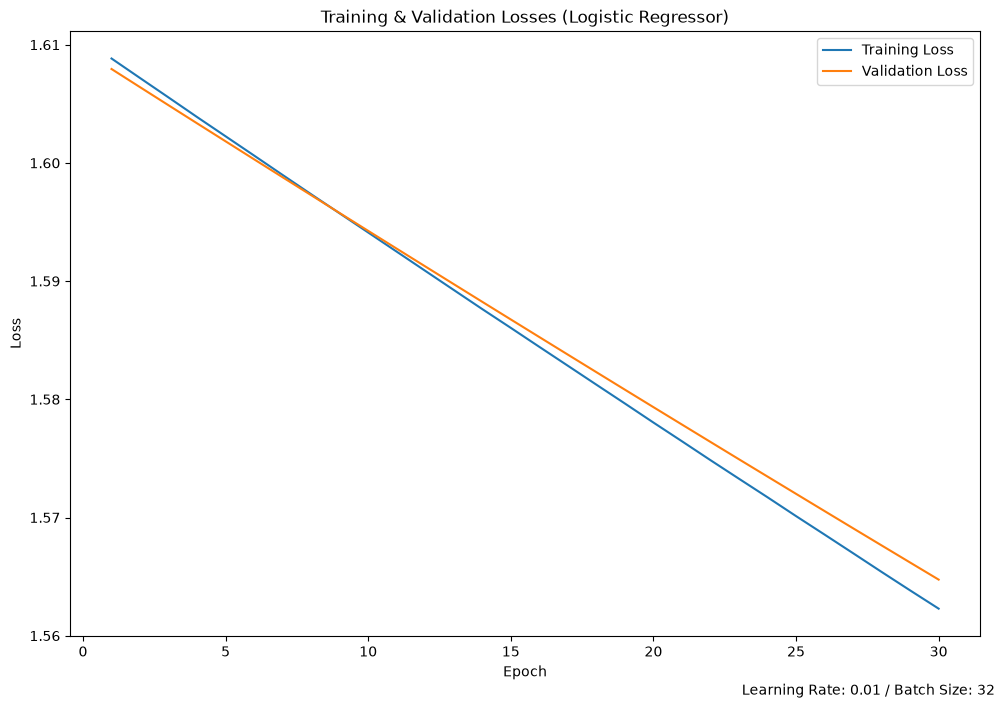

In [14]:
plt.figure(figsize=(10, 7))

plt.plot(EPOCHS, training_losses, label="Training Loss")
plt.plot(EPOCHS, validation_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title("Training & Validation Losses (Logistic Regressor)")

plt.figtext(1, 0, f"Learning Rate: {LEARNING_RATE} / Batch Size: {BATCH_SIZE}", ha="right")

plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(10, 7))

plt.plot(EPOCHS, training_accuracies, label="Training Accuracy")
plt.plot(EPOCHS, validation_accuracies, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title("Training & Validation Accuracies (Logistic Regressor)")

plt.figtext(1, 0, f"Learning Rate: {LEARNING_RATE} / Batch Size: {BATCH_SIZE}", ha="right")

plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(10, 7))

plt.plot(
    EPOCHS,
    training_f1macros,
    label="Training Macro-F1"
)

plt.plot(
    EPOCHS,
    validation_f1macros,
    label="Validation Macro-F1"
)

plt.plot(
    EPOCHS,
    training_f1s,
    label="Training F1 (Weighted)"
)

plt.plot(
    EPOCHS,
    validation_f1s,
    label="Validation F1 (Weighted)"
)

plt.xlabel("Epoch")
plt.ylabel("F1 Score")

plt.title("Training & Validation Macro-F1/F1 Scores (Logistic Regressor)")

plt.figtext(1, 0, f"Learning Rate: {LEARNING_RATE} / Batch Size: {BATCH_SIZE}", ha="right")

plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(10, 7))

plt.plot(
    EPOCHS,
    training_precisions,
    label="Training Precision"
)

plt.plot(
    EPOCHS,
    validation_precisions,
    label="Validation Precision"
)

plt.plot(
    EPOCHS,
    training_recalls,
    label="Training Recall"
)

plt.plot(
    EPOCHS,
    validation_recalls,
    label="Validation Recall"
)

plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Training & Validation Precision/Recall (Logistic Regressor)")

plt.ylim(0, 1)

plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
cm = confusion_matrix(
    validation_trues,
    validation_predictions
)

cm_display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=LABELS["Set A"].to_list())  # overriding display_labels to show the actual labels
cm_display.plot(values_format='d')

plt.title("Validation Confusion Matrix (Logistic Regressor)")

plt.figtext(1, 0, f"Learning Rate: {LEARNING_RATE} / Batch Size: {BATCH_SIZE}", ha="right")

plt.tight_layout()
plt.show()

### Custom Multi-Layer Perceptron

The model consists of the following layers:
1. Input Layer: input_dim
2. Hidden Layer 1: 256 neurons $\to$ ReLU activation $\to$ Dropout($p=0.1$)
3. Hidden Layer 2: 128 neurons $\to$ ReLU activation $\to$ Dropout($p=0.4$)
5. Output Layer: output_dim (number of labels)

Loss Function: Cross-Entropy

Optimizer: SGD

In [15]:
class CustomMLP(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.1),

            nn.Linear(256 ,128),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(128, output_dim)
        )

    def forward(self, x):
        return self.layers(x)

In [16]:
# Constants & Hyperparameters
MAX_EPOCH = 35  # TODO: maybe we can do some early stopping during the training process

LEARNING_RATE = 0.021
MOMENTUM = 0.9
WEIGHT_DECAY = 0.0017

In [17]:
model = CustomMLP(a_train_tensor.shape[1], LABELS_A_NUNIQUE).to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=LEARNING_RATE, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY)

In [18]:
training_losses = []
validation_losses = []

training_accuracies = []
validation_accuracies = []

training_f1macros = []
training_f1s = []
training_precisions = []
training_recalls = []

validation_f1macros = []
validation_f1s = []
validation_precisions = []
validation_recalls = []

for epoch in range(MAX_EPOCH):
    print(f"Epoch: {epoch + 1:02}/{MAX_EPOCH}", end='')
    # Training
    model.train()

    training_loss = 0  # compute the cumulative loss within an epoch
    training_accuracy = 0

    training_predictions = []
    training_trues = []

    for i, (x, y) in enumerate(a_train_loader):
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)

        logits = model(x)

        loss = criterion(logits, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # multiply by batch size to get the total loss for this batch
        training_loss += loss.item() * x.size(0)

        predictions = torch.argmax(logits, dim=1)

        training_predictions.extend(predictions.detach().cpu().numpy())
        training_trues.extend(y.cpu().numpy())

        training_accuracy += (predictions == y).sum().item()

    training_loss /= len(a_train_dataset)
    training_accuracy /= len(a_train_dataset)

    training_losses.append(training_loss)
    training_accuracies.append(training_accuracy)

    training_f1macro = f1_score(training_trues, training_predictions, average="macro", zero_division=0)
    training_f1macros.append(training_f1macro)

    training_f1 = f1_score(training_trues, training_predictions, average="weighted", zero_division=0)
    training_f1s.append(training_f1)

    training_precision = precision_score(training_trues, training_predictions, average="weighted", zero_division=0)
    training_precisions.append(training_precision)

    training_recall = recall_score(training_trues, training_predictions, average="weighted", zero_division=0)
    training_recalls.append(training_recall)

    # Validation
    model.eval()

    validation_loss = 0
    validation_accuracy = 0

    validation_predictions = []
    validation_trues = []

    with torch.inference_mode():
        for i, (x, y) in enumerate(a_validation_loader):
            x = x.to(DEVICE, non_blocking=True)
            y = y.to(DEVICE, non_blocking=True)

            logits = model(x)

            loss = criterion(logits, y)

            validation_loss += loss.item() * x.size(0)

            predictions = torch.argmax(logits, dim=1)

            validation_predictions.extend(predictions.detach().cpu().numpy())
            validation_trues.extend(y.cpu().numpy())

            validation_accuracy += (predictions == y).sum().item()

    validation_loss /= len(a_validation_dataset)
    validation_accuracy /= len(a_validation_dataset)

    validation_losses.append(validation_loss)
    validation_accuracies.append(validation_accuracy)

    validation_f1macro = f1_score(validation_trues, validation_predictions, average="macro", zero_division=0)
    validation_f1macros.append(validation_f1macro)

    validation_f1 = f1_score(validation_trues, validation_predictions, average="weighted", zero_division=0)
    validation_f1s.append(validation_f1)

    validation_precision = precision_score(validation_trues, validation_predictions, average="weighted", zero_division=0)
    validation_precisions.append(validation_precision)

    validation_recall = recall_score(validation_trues, validation_predictions, average="weighted", zero_division=0)
    validation_recalls.append(validation_recall)

    print("\tDone!")

Epoch: 01/35	Done!
Epoch: 02/35	Done!
Epoch: 03/35	Done!
Epoch: 04/35	Done!
Epoch: 05/35	Done!
Epoch: 06/35	Done!
Epoch: 07/35	Done!
Epoch: 08/35	Done!
Epoch: 09/35	Done!
Epoch: 10/35	Done!
Epoch: 11/35	Done!
Epoch: 12/35	Done!
Epoch: 13/35	Done!
Epoch: 14/35	Done!
Epoch: 15/35	Done!
Epoch: 16/35	Done!
Epoch: 17/35	Done!
Epoch: 18/35	Done!
Epoch: 19/35	Done!
Epoch: 20/35	Done!
Epoch: 21/35	Done!
Epoch: 22/35	Done!
Epoch: 23/35	Done!
Epoch: 24/35	Done!
Epoch: 25/35	Done!
Epoch: 26/35	Done!
Epoch: 27/35	Done!
Epoch: 28/35	Done!
Epoch: 29/35	Done!
Epoch: 30/35	Done!
Epoch: 31/35	Done!
Epoch: 32/35	Done!
Epoch: 33/35	Done!
Epoch: 34/35	Done!
Epoch: 35/35	Done!


In [19]:
EPOCHS = range(1, MAX_EPOCH + 1)

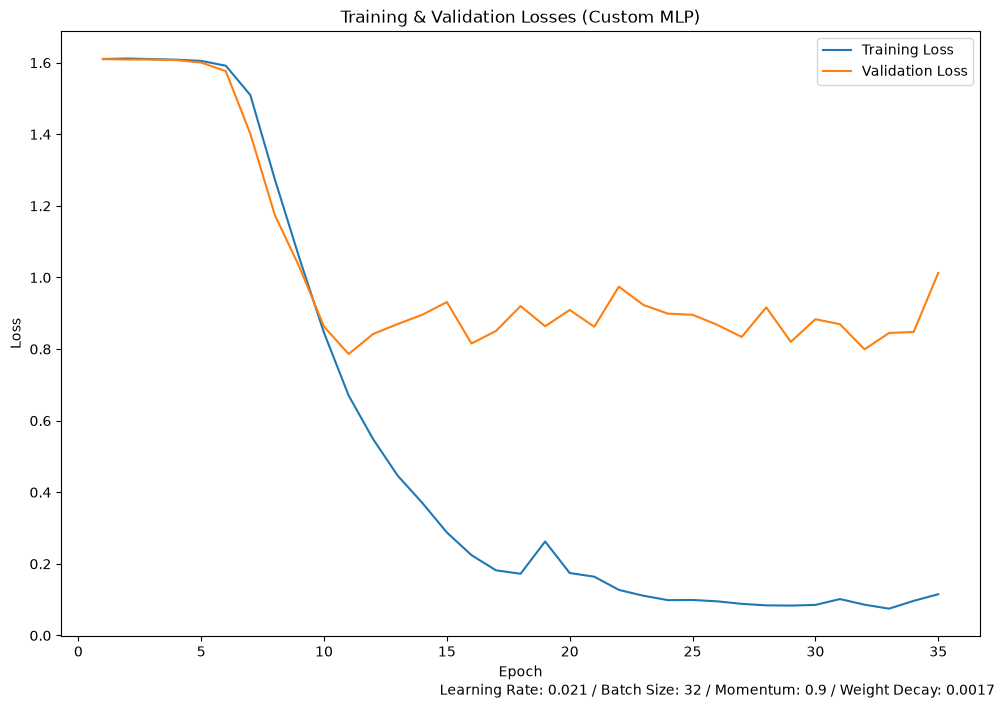

In [20]:
plt.figure(figsize=(10, 7))

plt.plot(EPOCHS, training_losses, label="Training Loss")
plt.plot(EPOCHS, validation_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title("Training & Validation Losses (Custom MLP)")

plt.figtext(1, 0, f"Learning Rate: {LEARNING_RATE} / Batch Size: {BATCH_SIZE} / Momentum: {MOMENTUM} / Weight Decay: {WEIGHT_DECAY}", ha="right")

plt.legend()

plt.tight_layout()
plt.show()

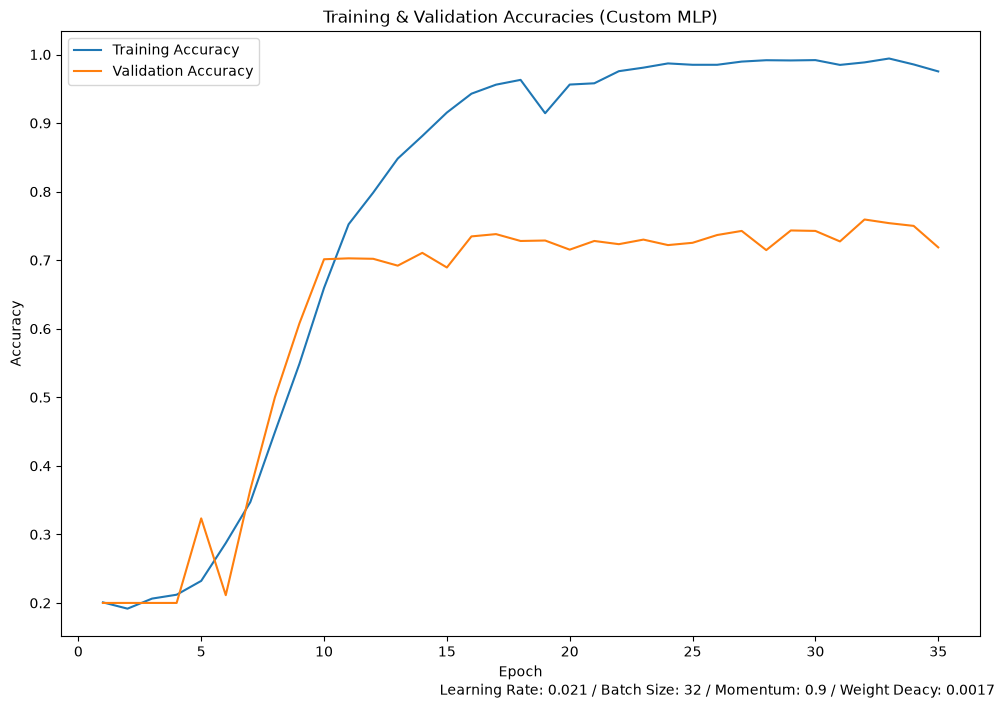

In [21]:
plt.figure(figsize=(10, 7))

plt.plot(EPOCHS, training_accuracies, label="Training Accuracy")
plt.plot(EPOCHS, validation_accuracies, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title("Training & Validation Accuracies (Custom MLP)")

plt.figtext(1, 0, f"Learning Rate: {LEARNING_RATE} / Batch Size: {BATCH_SIZE} / Momentum: {MOMENTUM} / Weight Deacy: {WEIGHT_DECAY}", ha="right")

plt.legend()

plt.tight_layout()
plt.show()

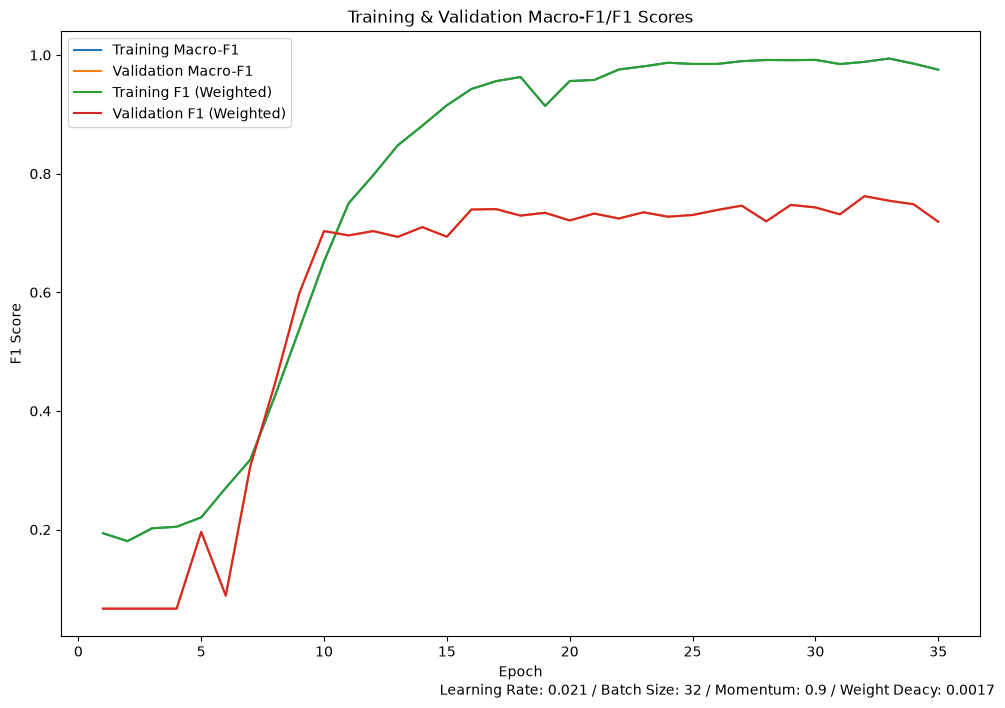

In [22]:
plt.figure(figsize=(10, 7))

plt.plot(
    EPOCHS,
    training_f1macros,
    label="Training Macro-F1"
)

plt.plot(
    EPOCHS,
    validation_f1macros,
    label="Validation Macro-F1"
)

plt.plot(
    EPOCHS,
    training_f1s,
    label="Training F1 (Weighted)"
)

plt.plot(
    EPOCHS,
    validation_f1s,
    label="Validation F1 (Weighted)"
)

plt.xlabel("Epoch")
plt.ylabel("F1 Score")

plt.title("Training & Validation Macro-F1/F1 Scores (Custom MLP)")

plt.figtext(1, 0, f"Learning Rate: {LEARNING_RATE} / Batch Size: {BATCH_SIZE} / Momentum: {MOMENTUM} / Weight Deacy: {WEIGHT_DECAY}", ha="right")

plt.legend()

plt.tight_layout()
plt.show()

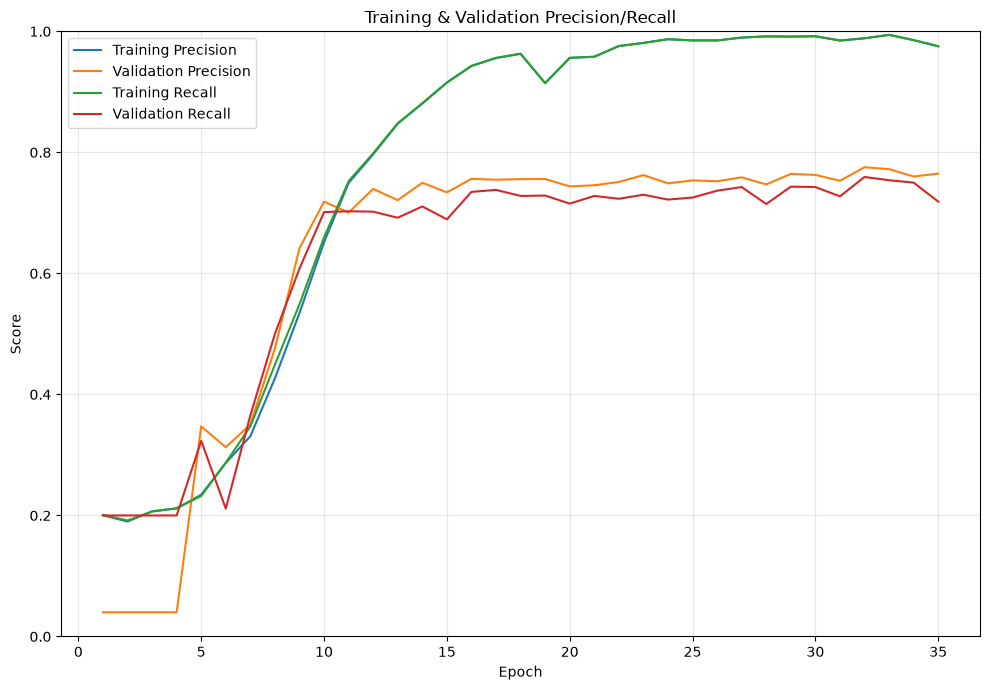

In [23]:
plt.figure(figsize=(10, 7))

plt.plot(
    EPOCHS,
    training_precisions,
    label="Training Precision"
)

plt.plot(
    EPOCHS,
    validation_precisions,
    label="Validation Precision"
)

plt.plot(
    EPOCHS,
    training_recalls,
    label="Training Recall"
)

plt.plot(
    EPOCHS,
    validation_recalls,
    label="Validation Recall"
)

plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Training & Validation Precision/Recall (Custom MLP)")

plt.figtext(1, 0, f"Learning Rate: {LEARNING_RATE} / Batch Size: {BATCH_SIZE} / Momentum: {MOMENTUM} / Weight Deacy: {WEIGHT_DECAY}", ha="right")

plt.legend()

plt.tight_layout()
plt.show()

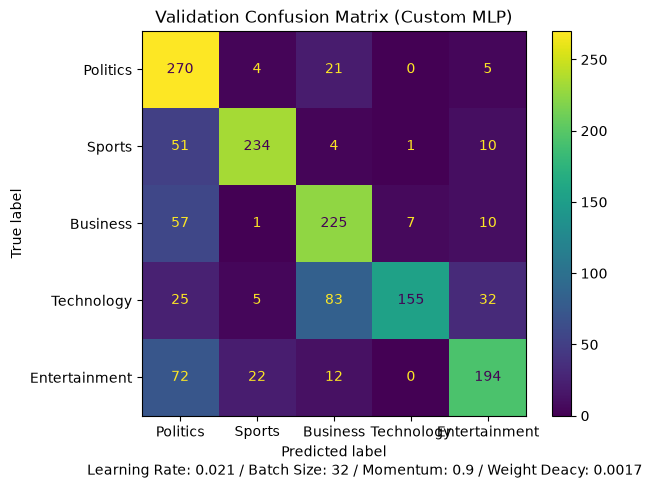

In [24]:
cm = confusion_matrix(
    validation_trues,
    validation_predictions
)

cm_display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=LABELS["Set A"].to_list())  # overriding display_labels to show the actual labels
cm_display.plot(values_format='d')

plt.title("Validation Confusion Matrix (Custom MLP)")

plt.figtext(1, 0, f"Learning Rate: {LEARNING_RATE} / Batch Size: {BATCH_SIZE} / Momentum: {MOMENTUM} / Weight Deacy: {WEIGHT_DECAY}", ha="right")

plt.tight_layout()
plt.show()

## Refit & Test

In [25]:
a_test_tfidf = vectorizer.transform(SOURCE_A_TEST.apply(concat_article, axis=1))

a_test_tensor = torch.tensor(a_test_tfidf.toarray(), dtype=torch.float32).to(DEVICE)
print(a_test_tensor)

a_test_labels_tensor = torch.tensor((SOURCE_A_TEST["Label"] - 1).to_list(), dtype=torch.long).to(DEVICE)
print(a_test_labels_tensor)

tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]], device='cuda:0')
tensor([3, 1, 1,  ..., 1, 3, 0], device='cuda:0')


In [26]:
a_test_dataset = TensorDataset(
    a_test_tensor.cpu(),
    a_test_labels_tensor.cpu()
)

a_test_loader = DataLoader(
    a_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=USE_CUDA
)

In [27]:
testing_predictions = []
testing_trues = []

misclassified_predictions = []

model.eval()

with torch.inference_mode():
    for i, (x, y) in enumerate(a_test_loader):
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)

        logits = model(x)

        probabilities = torch.softmax(logits, dim=1)
        predictions = torch.argmax(logits, dim=1)

        testing_predictions.extend(predictions.detach().cpu().numpy())
        testing_trues.extend(y.cpu().numpy())

testing_accuracy = accuracy_score(testing_trues, testing_predictions)

print(testing_accuracy)


0.4676


## Examining Misclassified Cases

In [29]:
misclassified_idx = np.where(np.array(testing_trues) != np.array(testing_predictions))[0]
print(misclassified_idx)

misclassified_entries = SOURCE_A_TEST.iloc[misclassified_idx].copy()

display(misclassified_entries.head(10))

[   0    1    2 ... 2497 2498 2499]


,Label,Title,Description
0,4,Police Officials Tell Congress Encryption Hurt...,The encryption debate returned to Congress on ...
1,2,Wisconsin Apologizes For Mishandling Fans Depi...,“We will learn from this incident and do bette...
2,2,Karl-Anthony Towns Carves His Own Path As The ...,The Minnesota center is a playmaking 7-footer ...
5,1,What Is Kanye West's iPhone Password?,😱😱😱😱😱😱
6,3,Move The Starting Line: COO Knows Diverse Team...,"Yes, she knows it sounds odd coming from someo..."
8,5,Here's How The 'Legally Blonde' Bend And Snap ...,It's the only move that has an 83-percent retu...
10,5,Kanye West Tweets Fake Harriet Tubman Quote Af...,There's no evidence the activist said the quot...
12,2,Trump Posthumously Pardons Boxer Jack Johnson,The pardoning of the black heavyweight boxer i...
14,1,Migrant Women Reportedly Kept From Speaking To...,They said they were moved to a soccer field fo...
16,4,LinkedIn Users Might Want To Change All Of The...,This is bad.
